# Data Merging and Deduplication

Harmonizes and deduplicates papers from four sources (Scopus, ACL Anthology, Semantic Scholar, Web of Science) into a single dataset.

**Four-stage graph merge:**
- Stage 1 — DOI (non-arXiv, exact)
- Stage 2 — ACL ID (Available only for ACL Anthology and Semantic Scholar)
- Stage 3 — arXiv ID (exact, across all source-specific fields)
- Stage 4 — normalized title + year window (fuzzy, rapidfuzz)

In [14]:
import sys
sys.path.append("../")  # go up one level from notebooks/ to project root (for using src/)

import json
import logging
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import pandas as pd
import openpyxl

from src.data_loading import load_all_sources
from src.data_merge import minimal_merge
from src.utils import venn_matrix

logging.basicConfig(level=logging.INFO, format="%(name)s %(levelname)s %(message)s")

## Load Sources

In [15]:
records = load_all_sources({"scopus": "../data/raw/scopus/scopus_data.jsonl",
                            "acl":    "../data/raw/acl/acl_data.jsonl",
                            "wos":    "../data/raw/wos/wos_data.txt",
                            "semantic_scholar": "../data/raw/semantic_scholar/semantic_scholar_data.jsonl"})
counts = Counter(r["_source"] for r in records)
print(f"Total records loaded: {len(records)}")
for src, n in sorted(counts.items()):
    print(f"  {src}: {n}")

src.data_loading INFO Scopus: loaded 123 records from ../data/raw/scopus/scopus_data.jsonl
src.data_loading INFO ACL: loaded 7 records from ../data/raw/acl/acl_data.jsonl


src.data_loading INFO Semantic Scholar: loaded 90 records from ../data/raw/semantic_scholar/semantic_scholar_data.jsonl
src.data_loading INFO WoS: loaded 83 records from ../data/raw/wos/wos_data.txt
src.data_loading INFO Total records loaded: 303 from 4 source(s)


Total records loaded: 303
  acl: 7
  scopus: 123
  semantic_scholar: 90
  wos: 83


In [16]:
records[0]

{'wos_id': None,
 'acl_id': None,
 'scopus_eid': '2-s2.0-105031784192',
 'semantic_scholar_id': None,
 'doi': '10.1016/j.knosys.2026.115668',
 'acl_anthology_id': None,
 'arxiv_id': None,
 'title': 'SABER: Integrating sentiment and stance detection for climate change discourse on social media',
 'abstract': 'As the severity of climate change intensifies, understanding public attitudes toward this pressing issue is crucial for developing effective mitigation strategies. Social media platforms have emerged as influential tools for shaping and reflecting public opinions on climate change. However, the discourse on these platforms is deeply polarized, divided between those who acknowledge the urgency of the situation and those who maintain a skeptical stance, often fueled by misinformation and denial. This stark divide underscores the necessity of disseminating accurate information and developing effective climate change mitigation strategies, making stance detection a vital task in this d

DOI and arXiv ID Coverage

In [17]:
coverage = []
for src, total in counts.items():
    src_recs = [r for r in records if r["_source"] == src]
    n_doi   = sum(1 for r in src_recs if r["doi"])
    n_acl_id = sum(1 for r in src_recs if r["acl_anthology_id"])
    n_arxiv = sum(1 for r in src_recs if r["arxiv_id"])
    coverage.append({
        "source": src, "total": total,
        "has_doi": n_doi, "doi_%": f"{n_doi/total*100:.0f}%",
        "has_acl_id": n_acl_id, "acl_%": f"{n_acl_id/total*100:.0f}%",
        "has_arxiv_id": n_arxiv, "arxiv_%": f"{n_arxiv/total*100:.0f}%",
    })
pd.DataFrame(coverage).set_index("source")

,total,has_doi,doi_%,has_acl_id,acl_%,has_arxiv_id,arxiv_%
source,,,,,,,
scopus,123,105,85%,0,0%,0,0%
acl,7,6,86%,7,100%,0,0%
semantic_scholar,90,73,81%,2,2%,17,19%
wos,83,79,95%,0,0%,0,0%


## Minimal Merge

Not a complete data harmonization. Deduplicates papers and provides their title, year, abstract and venue. No normalization for venue names, just a simple merge of all available metadata fields.

In [18]:
merged, G = minimal_merge(records=records)
print(f"Before dedup : {len(records)} records")
print(f"After dedup  : {len(merged)} unique papers")
print(f"Edges in graph: {G.number_of_edges()}")

src.data_merge INFO Stage 4 match (score=100.0, years=2024/2024): 'Granular Analysis of Social Media Users’ Truthfulness Stance' | 'Granular Analysis of Social Media Users' Truthfulness Stance'
src.data_merge INFO Stage 4 match (score=100.0, years=2024/2024): 'Exploring the Network and Topic Stability in Climate Change ' | 'Exploring the Network and Topic Stability in Climate Change '
src.data_merge INFO Stage 4 match (score=100.0, years=2024/2024): 'Leveraging fine-tuned Large Language Models with LoRA for Ef' | 'Leveraging fine-tuned Large Language Models with LoRA for Ef'
src.data_merge INFO Stage 4 match (score=100.0, years=2025/2025): 'Fine-grained Fallacy Detection with Human Label Variation' | 'Fine-grained Fallacy Detection with Human Label Variation'
src.data_merge INFO Stage 4 match (score=100.0, years=2024/2024): 'Granular Analysis of Social Media Users’ Truthfulness Stance' | 'Granular Analysis of Social Media Users’ Truthfulness Stance'
src.data_merge INFO Stage 4 match (s

Before dedup : 303 records
After dedup  : 186 unique papers
Edges in graph: 117


## Deduplication Statistics

In [19]:
meta_path = Path("../data/processed/merged_minimal_meta.json")
meta = json.loads(meta_path.read_text())
print(f"Input records      : {meta['n_input_records']}")
print(f"Output records     : {meta['n_output_records']}")
print(f"Stage 1 (DOI)      : {meta['n_doi_edges']} edges")
print(f"Stage 2 (ACL ID)   : {meta['n_acl_edges']} edges")
print(f"Stage 3 (arXiv)    : {meta['n_arxiv_edges']} edges")
print(f"Stage 4 (title+yr) : {meta['n_title_year_edges']} edges")
print(f"Singletons         : {meta['n_singletons']}")
print(f"Content conflicts  : {meta['n_content_conflicts']}")
print("\nConflicts by field:", meta["n_conflicts_by_field"])
print("\nSource file hashes:")
for src, h in meta["source_hashes"].items():
    print(f"  {src}: {h}")

Input records      : 303
Output records     : 186
Stage 1 (DOI)      : 106 edges
Stage 2 (ACL ID)   : 0 edges
Stage 3 (arXiv)    : 0 edges
Stage 4 (title+yr) : 11 edges
Singletons         : 111
Content conflicts  : 75

Conflicts by field: {'abstract': 48, 'year': 13, 'title': 14, 'doi': 1}

Source file hashes:
  scopus: eb5ee2381ebabc6786884fcd5f2c9152
  acl: d5a4f5c72cc7d89e2abe051bb19e6f09
  semantic_scholar: 03bf21e58ae2317bebcc115d4be0da13
  wos: a9de9deaaa647f3b996e3fab219fa8f2


Source Distribution

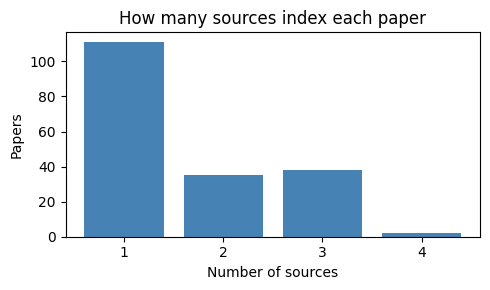

  1 source(s): 111 papers
  2 source(s): 35 papers
  3 source(s): 38 papers
  4 source(s): 2 papers


In [20]:
n_sources_dist = Counter(len(r["sources"]) for r in merged)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(n_sources_dist.keys(), n_sources_dist.values(), color="steelblue")
ax.set_xlabel("Number of sources")
ax.set_ylabel("Papers")
ax.set_title("How many sources index each paper")
ax.set_xticks(sorted(n_sources_dist.keys()))
plt.tight_layout()
plt.show()
for n, count in sorted(n_sources_dist.items()):
    print(f"  {n} source(s): {count} papers")

## Conflict Analysis

In [21]:
conflict_rows = [
    {
        "paper_id": rec["paper_id"], 
        "doi": rec.get("doi", ""),
        "field": field, 
        "conflict_type": c["conflict_type"],
        "sources": ", ".join(str(v["source"]) for v in c["values"]),
        "values": " | ".join(str(v["value"]) for v in c["values"]),
    }
    for rec in merged
    for field, c in rec.get("_conflicts", {}).items()
]
cdf = pd.DataFrame(conflict_rows)
if cdf.empty:
    print("No conflicts.")
else:
    print(cdf.groupby(["field", "conflict_type"]).size().to_string())
    print("\n--- Content conflicts (first 20) ---")
    pd.set_option("display.max_colwidth", 100)
    print(conflict_rows)
    # display(cdf[cdf["conflict_type"] == "content"][["field", "doi", "sources", "values"]].head(20))

field     conflict_type
abstract  content          47
          formatting        1
doi       content           1
title     content          14
year      content          13

--- Content conflicts (first 20) ---
[{'paper_id': '1245b0fc7d9ed4a1', 'doi': '10.5220/0011632000003323', 'field': 'abstract', 'conflict_type': 'content', 'sources': 'scopus, semantic_scholar', 'values': "Many of the issues in the modern world are complex and multifaceted: migration, banking, not to mention climate change and Covid. Furthermore, social-media, which at first seemed to offer more reliable 'on the ground' citizen journalism, has instead become a seedbed of dis-information. Trust in media has plummeted, just when it has become essential. This is a problem, but also an opportunity for research in HCI that can make a real difference in the world. The majority of work in this area, from various disciplines including datascience, AI and HCI, is focused on combatting misinformation - fighting back against 

Matches Review at stage 4 (title+year) only, as these are the most likely to contain false positives. 

In [22]:
stage4_edges = [(u, v, d) for u, v, d in G.edges(data=True) if d["match_stage"] == 4]
print(f"Stage 4 (title+year) edges: {len(stage4_edges)}")
rows = [{
    "score": d["match_key"],
    "source_u": G.nodes[u]["_source"], "source_v": G.nodes[v]["_source"],
    "year_u": G.nodes[u].get("year"), "year_v": G.nodes[v].get("year"),
    "title_u": (G.nodes[u].get("title") or "")[:70],
    "title_v": (G.nodes[v].get("title") or "")[:70],
} for u, v, d in stage4_edges]
display(pd.DataFrame(rows))

Stage 4 (title+year) edges: 11


,score,source_u,source_v,year_u,year_v,title_u,title_v
0,100.0,scopus,semantic_scholar,2026,2026,Measuring Social Media Polarization Using Large Language Models and He,Measuring Social Media Polarization Using Large Language Models and He
1,100.0,scopus,semantic_scholar,2026,2025,Sentiment and Social Signals in the Climate Crisis: A Survey on Analyz,Sentiment and Social Signals in the Climate Crisis: A Survey on Analyz
2,100.0,scopus,semantic_scholar,2025,2024,Two-Stage Stance Labeling: User-Hashtag Heuristics with Graph Neural N,Two-Stage Stance Labeling: User-Hashtag Heuristics with Graph Neural N
3,100.0,scopus,wos,2025,2025,Fine-grained Fallacy Detection with Human Label Variation,Fine-grained Fallacy Detection with Human Label Variation
4,100.0,scopus,acl,2024,2024,A Few Hypocrites: Few-Shot Learning and Subtype Definitions for Detect,A Few Hypocrites: Few-Shot Learning and Subtype Definitions for Detect
5,100.0,scopus,wos,2024,2024,Granular Analysis of Social Media Users’ Truthfulness Stances Toward C,Granular Analysis of Social Media Users' Truthfulness Stances Toward C
6,100.0,scopus,semantic_scholar,2024,2024,Granular Analysis of Social Media Users’ Truthfulness Stances Toward C,Granular Analysis of Social Media Users’ Truthfulness Stances Toward C
7,100.0,scopus,wos,2024,2024,Exploring the Network and Topic Stability in Climate Change Deniers' D,Exploring the Network and Topic Stability in Climate Change Deniers' D
8,100.0,scopus,wos,2024,2024,Leveraging fine-tuned Large Language Models with LoRA for Effective Cl,Leveraging fine-tuned Large Language Models with LoRA for Effective Cl
9,100.0,scopus,semantic_scholar,2024,2024,Leveraging fine-tuned Large Language Models with LoRA for Effective Cl,Leveraging fine-tuned Large Language Models with LoRA for Effective Cl


## Screening files

File for the researchers to screen for relevance to the papers. The `screening.xlsx` file contains all papers present in multiple sources. 

In [23]:
flat = [
    {
        "paper_id": r["paper_id"],
        "ids": ", ".join(
            f"{id}: {r.get(id)}"
            for id in ["doi", "arxiv_id", "wos_id", "acl_id", "scopus_eid", "semantic_scholar_id"]
            if r.get(id)
        ),
        "year": r.get("year"),
        "sources": ", ".join(r["sources"]),
        "title": (r.get("title") or ""),
        "abstract": (r.get("abstract") or ""),
        "published_in": ", ".join(f"{src}: {v}" for src, v in r.get("published_in", {}).items()),
        "paper_type": ", ".join(f"{src}: {v}" for src, v in r.get("paper_type", {}).items())
    }
    for r in merged
]

screening = pd.DataFrame(flat)

In [24]:
# Do not export to CSV since abstracts can contain characters that interfere with separators. Excel can handle multiline text in cells more gracefully.
output_path = Path("../data/processed/screening.xlsx")
screening.to_excel(output_path, index=False)

# Sample for IAA 

## First Round

Subsets for IAA. 

- 3 annotators
- Same 20 papers for the 3 annotators + 10 papers for each pairwise combination = 40 papers per annotator.


In [ ]:
import numpy as np
from itertools import combinations

annotators = ["MC", "ME", "TC"]
n_per_pair = 10
n_all = 20

rng = np.random.default_rng(seed=42)
n = len(screening)

pairs = list(combinations(annotators, 2))
pair_labels = {p: f"pair_{'_'.join(p)}" for p in pairs}

iaa_labels = (
    [pair_labels[p] for p in pairs for _ in range(n_per_pair)]
    + ["all"] * n_all
    + ["unselected"] * (n - len(pairs) * n_per_pair - n_all)
)
rng.shuffle(iaa_labels)

screening = screening.assign(iaa_set=iaa_labels)

ANNOTATOR_SETS = {
    ann: {"all"} | {pair_labels[p] for p in pairs if ann in p}
    for ann in annotators
}

iaa_dir = Path("../data/processed/iaa/raw/round1")
iaa_dir.mkdir(exist_ok=True)

for annotator, included in ANNOTATOR_SETS.items():
    subset = (
        screening
        .loc[screening["iaa_set"].isin(included)]
        .reset_index(drop=True)
        [["iaa_set"] + [c for c in screening.columns if c != "iaa_set"]]
    )
    subset.to_excel(iaa_dir / f"annotator_{annotator}.xlsx", index=False)
    print(f"Annotator {annotator}: {len(subset)} rows "
          f"({subset['iaa_set'].value_counts().to_dict()})")


Annotator MC: 40 rows ({'all': 20, 'pair_MC_ME': 10, 'pair_MC_TC': 10})
Annotator ME: 40 rows ({'all': 20, 'pair_MC_ME': 10, 'pair_ME_TC': 10})
Annotator TC: 40 rows ({'all': 20, 'pair_ME_TC': 10, 'pair_MC_TC': 10})


## Second Round

Same 20 papers for the 3 annotators. 
No pairwise combination papers. 
Papers used in the first round are excluded from the sampling pool. 

In [37]:
round2_dir = Path("../data/processed/iaa/raw/round2")
round2_dir.mkdir(parents=True, exist_ok=True)

round2 = (
    screening
    .loc[screening["iaa_set"] == "unselected"]
    .drop(columns="iaa_set")
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

for annotator in annotators:
    round2.to_excel(round2_dir / f"annotator_{annotator}.xlsx", index=False)

print(f"Round 2: {len(round2)} papers saved for annotators {annotators}")


Round 2: 20 papers saved for annotators ['MC', 'ME', 'TC']
